# Notebook 06 — Confusion Matrices for ML, Deep Learning, and Federated Models

**Project:** Future water-quality class prediction  
**Purpose:** Generate thesis-ready row-normalized confusion matrices from already-saved predictions.

This updated N06 reads the final outputs from:

- N03 — GRU baselines
- N04 — LSTM baselines
- N05 — Transformer baselines
- N08 — Classical ML baselines

It does **not** train any model. It only loads saved test predictions and produces confusion-matrix evidence for:

1. all local classical ML models;
2. all centralized classical ML models;
3. all local deep-learning models;
4. all centralized deep-learning models;
5. all available federated deep-learning variants;
6. best local model per client;
7. best centralized model per client;
8. best available federated model per client;
9. best deep-learning model per client.

## Important scientific note

This notebook can only draw a confusion matrix when `y_true` and `y_pred` are available. If a previous notebook saved only metrics for a model variant but did not save its predictions, N06 cannot reconstruct the confusion matrix from metrics alone.


In [31]:
# 0.1 — Imports
import os
import re
import zipfile
import warnings
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)
from IPython.display import display

warnings.filterwarnings("ignore")
print("Imports ready.")

Imports ready.


In [32]:
# 0.2 — Constants and folders
ACTIVE_CLIENTS = ["England", "Ireland", "USA"]
CLASS_NAMES = ["Excellent", "Good", "Fair", "Marginal", "Poor"]
N_CLASSES = len(CLASS_NAMES)

INPUT_ROOT = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path("/mnt/data")
WORKING_ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("/mnt/data/n06_working")
OUTPUT_DIR = WORKING_ROOT / "confusion_matrices"
EXTRACT_DIR = WORKING_ROOT / "_extracted_n06_sources"

# Reset output folder to avoid mixing old and new figures
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Input root  : {INPUT_ROOT}")
print(f"Working dir : {WORKING_ROOT}")
print(f"Output dir  : {OUTPUT_DIR}")

Input root  : /kaggle/input
Working dir : /kaggle/working
Output dir  : /kaggle/working/confusion_matrices


## 1. Extract and locate prediction sources

This section extracts the attached output zips if needed and searches both `/kaggle/input` and the extracted folder.


In [33]:
# 1.1 — Extract required zipped outputs if present
ZIP_KEYWORDS = [
    "gru_baselines",
    "lstm_baselines",
    "transformer_baselines",
    "classical_ml_baselines",
    "n08_classical_ml_baselines",
]

found_zips = []
if INPUT_ROOT.exists():
    for p in INPUT_ROOT.rglob("*.zip"):
        lname = p.name.lower().replace("-", "_")
        if any(k in lname for k in ZIP_KEYWORDS):
            found_zips.append(p)

print("Candidate zips found:")
for p in found_zips:
    print(" -", p)

for zpath in found_zips:
    safe_stem = re.sub(r"[^a-zA-Z0-9_]+", "_", zpath.stem)
    target = EXTRACT_DIR / safe_stem
    marker = target / ".extracted"
    if marker.exists():
        print(f"Already extracted: {zpath.name}")
        continue
    print(f"Extracting {zpath.name} -> {target}")
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zpath, "r") as zf:
        zf.extractall(target)
    marker.write_text("done")

SEARCH_ROOTS = [INPUT_ROOT, EXTRACT_DIR]
print("\nSearch roots:")
for root in SEARCH_ROOTS:
    print(" -", root)

Candidate zips found:

Search roots:
 - /kaggle/input
 - /kaggle/working/_extracted_n06_sources


In [34]:
# 1.2 — Generic search helpers

def find_file(filename):
    candidates = []
    for root in SEARCH_ROOTS:
        if root.exists():
            candidates.extend(root.rglob(filename))
    candidates = sorted(set(candidates), key=lambda p: str(p))
    return candidates[0] if candidates else None


def find_prediction_dir(marker_file):
    path = find_file(marker_file)
    return path.parent if path is not None else None


def find_classical_prediction_file(model_key, strategy, client):
    client_l = client.lower()
    if strategy == "Local":
        filename = f"local_{model_key}_{client_l}_to_{client_l}_test_predictions.csv"
    elif strategy == "Centralized":
        filename = f"centralized_{model_key}_pooled_to_{client_l}_test_predictions.csv"
    else:
        raise ValueError(f"Unsupported classical strategy: {strategy}")
    return find_file(filename)


gru_pred_dir = find_prediction_dir("fedavg_v2_england_test_preds.npz")
lstm_pred_dir = find_prediction_dir("lstm_fedprox_v1_ireland_test_preds.npz")
tx_pred_dir = find_prediction_dir("local_transformer_england_test_preds.npz")

classical_marker = find_file("local_xgboost_england_to_england_test_predictions.csv")
classical_root_available = classical_marker is not None

print("Deep-learning prediction directories:")
print(f"GRU         : {gru_pred_dir}")
print(f"LSTM        : {lstm_pred_dir}")
print(f"Transformer : {tx_pred_dir}")
print("\nClassical ML predictions available:", classical_root_available)
if classical_marker is not None:
    print("Classical marker:", classical_marker)

assert gru_pred_dir is not None, "Updated GRU predictions not found. Attach the new gru_baselines zip containing fedavg_v2_england_test_preds.npz."
assert lstm_pred_dir is not None, "Updated LSTM predictions not found. Attach the new LSTM zip containing lstm_fedprox_v1_ireland_test_preds.npz."
assert tx_pred_dir is not None, "Transformer predictions not found. Attach transformer_baselines.zip."
assert classical_root_available, "Classical ML predictions not found. Attach N08_classical_ml_baselines_outputs.zip."

Deep-learning prediction directories:
GRU         : /kaggle/input/datasets/hebacheblal/gru-baselines/predictions
LSTM        : /kaggle/input/datasets/hebacheblal/lstm-baselines/predictions
Transformer : /kaggle/input/datasets/hebacheblal/transformer-baselines/predictions

Classical ML predictions available: True
Classical marker: /kaggle/input/datasets/hebacheblal/classical-ml-baselines/predictions/local_xgboost_england_to_england_test_predictions.csv


## 2. Build a unified prediction catalogue

The catalogue contains classical ML, deep-learning, and federated models whose **test predictions** are available.


In [35]:
# 2.1 — Prediction loading functions

def load_deep_preds(pred_dir, label, client):
    path = pred_dir / f"{label}_{client.lower()}_test_preds.npz"
    if not path.exists():
        return None, None, path
    arr = np.load(path)
    return arr["y_true"], arr["y_pred"], path


def load_classical_preds(model_key, strategy, client):
    path = find_classical_prediction_file(model_key, strategy, client)
    if path is None or not path.exists():
        return None, None, path
    df = pd.read_csv(path)
    return df["y_true"].to_numpy(), df["y_pred"].to_numpy(), path


def load_catalog_preds(item, client):
    if item["SourceType"] == "DeepNPZ":
        return load_deep_preds(item["PredDir"], item["Label"], client)
    if item["SourceType"] == "ClassicalCSV":
        return load_classical_preds(item["ModelKey"], item["Strategy"], client)
    raise ValueError("Unknown source type: " + str(item["SourceType"]))


def present_macro_f1(y_true, y_pred):
    present = sorted(np.unique(y_true).tolist())
    return f1_score(y_true, y_pred, labels=present, average="macro", zero_division=0)


def present_class_names(y_true):
    return ", ".join(CLASS_NAMES[i] for i in sorted(np.unique(y_true).tolist()))


def slugify(text):
    text = text.lower().replace("+", "plus")
    text = re.sub(r"[^a-z0-9]+", "_", text)
    return text.strip("_")

print("Loading helpers ready.")

Loading helpers ready.


In [36]:
# 2.2 — Model catalogue
MODEL_CATALOG = []

# Classical ML — local and centralized
CLASSICAL_MODELS = [
    ("Logistic_Regression", "logistic_regression"),
    ("Random_Forest", "random_forest"),
    ("XGBoost", "xgboost"),
    ("CatBoost", "catboost"),
]

for model_name, model_key in CLASSICAL_MODELS:
    for strategy in ["Local", "Centralized"]:
        MODEL_CATALOG.append({
            "Category": "Classical ML",
            "Family": model_name,
            "Strategy": strategy,
            "Model": f"{strategy} {model_name}",
            "SourceType": "ClassicalCSV",
            "ModelKey": model_key,
            "Label": f"{slugify(strategy)}_{slugify(model_name)}",
        })

# Deep learning and federated deep learning — saved .npz predictions
DEEP_ITEMS = [
    # GRU
    ("Deep learning", "GRU", "Local", "Local GRU", gru_pred_dir, "local"),
    ("Deep learning", "GRU", "Centralized", "Centralized GRU", gru_pred_dir, "centralized"),

    # All saved federated GRU variants.
    # This includes GRU FedAvg_v2, selected by N09 for England.
    ("Federated learning", "GRU", "Federated", "FedAvg GRU v1", gru_pred_dir, "fedavg_v1"),
    ("Federated learning", "GRU", "Federated", "FedAvg GRU v2", gru_pred_dir, "fedavg_v2"),
    ("Federated learning", "GRU", "Federated", "FedAvg GRU v3", gru_pred_dir, "fedavg_v3"),
    ("Federated learning", "GRU", "Federated", "FedProx GRU v1", gru_pred_dir, "fedprox_v1"),
    ("Federated learning", "GRU", "Federated", "FedProx GRU v2", gru_pred_dir, "fedprox_v2"),
    ("Federated learning", "GRU", "Federated", "FedProx GRU v3", gru_pred_dir, "fedprox_v3"),

    # LSTM
    ("Deep learning", "LSTM", "Local", "Local LSTM", lstm_pred_dir, "local_lstm"),
    ("Deep learning", "LSTM", "Centralized", "Centralized LSTM", lstm_pred_dir, "centralized_lstm"),

    # All saved federated LSTM variants.
    # These are needed so the exact LSTM FedProx_v1 confusion matrices can be generated.
    ("Federated learning", "LSTM", "Federated", "FedAvg LSTM v1", lstm_pred_dir, "lstm_fedavg_v1"),
    ("Federated learning", "LSTM", "Federated", "FedAvg LSTM v2", lstm_pred_dir, "lstm_fedavg_v2"),
    ("Federated learning", "LSTM", "Federated", "FedAvg LSTM v3", lstm_pred_dir, "lstm_fedavg_v3"),
    ("Federated learning", "LSTM", "Federated", "FedProx LSTM v1", lstm_pred_dir, "lstm_fedprox_v1"),
    ("Federated learning", "LSTM", "Federated", "FedProx LSTM v2", lstm_pred_dir, "lstm_fedprox_v2"),
    ("Federated learning", "LSTM", "Federated", "FedProx LSTM v3", lstm_pred_dir, "lstm_fedprox_v3"),

    # Transformer
    ("Deep learning", "Transformer", "Local", "Local Transformer", tx_pred_dir, "local_transformer"),
    ("Deep learning", "Transformer", "Centralized", "Centralized Transformer", tx_pred_dir, "centralized_transformer"),
    ("Federated learning", "Transformer", "Federated", "FedAvg Transformer v2", tx_pred_dir, "transformer_fedavg_v2"),
    ("Federated learning", "Transformer", "Federated", "FedProx Transformer v1", tx_pred_dir, "transformer_fedprox_v1"),
]

for category, family, strategy, model, pred_dir, label in DEEP_ITEMS:
    MODEL_CATALOG.append({
        "Category": category,
        "Family": family,
        "Strategy": strategy,
        "Model": model,
        "SourceType": "DeepNPZ",
        "PredDir": pred_dir,
        "Label": label,
    })

print(f"Catalogue size: {len(MODEL_CATALOG)} model configurations")
for item in MODEL_CATALOG:
    print(f"- {item['Category']} | {item['Strategy']} | {item['Model']}")

Catalogue size: 28 model configurations
- Classical ML | Local | Local Logistic_Regression
- Classical ML | Centralized | Centralized Logistic_Regression
- Classical ML | Local | Local Random_Forest
- Classical ML | Centralized | Centralized Random_Forest
- Classical ML | Local | Local XGBoost
- Classical ML | Centralized | Centralized XGBoost
- Classical ML | Local | Local CatBoost
- Classical ML | Centralized | Centralized CatBoost
- Deep learning | Local | Local GRU
- Deep learning | Centralized | Centralized GRU
- Federated learning | Federated | FedAvg GRU v1
- Federated learning | Federated | FedAvg GRU v2
- Federated learning | Federated | FedAvg GRU v3
- Federated learning | Federated | FedProx GRU v1
- Federated learning | Federated | FedProx GRU v2
- Federated learning | Federated | FedProx GRU v3
- Deep learning | Local | Local LSTM
- Deep learning | Centralized | Centralized LSTM
- Federated learning | Federated | FedAvg LSTM v1
- Federated learning | Federated | FedAvg LST

In [37]:
# 2.3 — Compute metrics for every available prediction set
rows = []
missing_rows = []

for item in MODEL_CATALOG:
    for client in ACTIVE_CLIENTS:
        y_true, y_pred, path = load_catalog_preds(item, client)
        base = {
            "Category": item["Category"],
            "Family": item["Family"],
            "Strategy": item["Strategy"],
            "Model": item["Model"],
            "Label": item["Label"],
            "Client": client,
            "SourceType": item["SourceType"],
            "Prediction_file": str(path) if path is not None else "",
        }
        if y_true is None:
            missing_rows.append({**base, "Found": False})
            rows.append({**base, "Found": False})
            continue

        rows.append({
            **base,
            "Found": True,
            "N": len(y_true),
            "Present_Classes": present_class_names(y_true),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
            "Macro_F1_Present": present_macro_f1(y_true, y_pred),
            "Weighted_F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        })

metrics_df = pd.DataFrame(rows)
missing_df = pd.DataFrame(missing_rows)

metrics_df.to_csv(OUTPUT_DIR / "n06_all_ml_dl_loaded_model_metrics.csv", index=False)
missing_df.to_csv(OUTPUT_DIR / "n06_missing_prediction_files.csv", index=False)

print("Saved metrics:", OUTPUT_DIR / "n06_all_ml_dl_loaded_model_metrics.csv")
print("Missing prediction files:", len(missing_df))
display(metrics_df[metrics_df["Found"] == True].sort_values(["Client", "Macro_F1_Present"], ascending=[True, False]).head(60))

Saved metrics: /kaggle/working/confusion_matrices/n06_all_ml_dl_loaded_model_metrics.csv
Missing prediction files: 0


,Category,Family,Strategy,Model,Label,Client,SourceType,Prediction_file,Found,N,Present_Classes,Accuracy,Balanced_Accuracy,Macro_F1_Present,Weighted_F1
12,Classical ML,XGBoost,Local,Local XGBoost,local_xgboost,England,ClassicalCSV,/kaggle/input/datasets/hebacheblal/classical-m...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.818037,0.701608,0.714501,0.818996
72,Deep learning,Transformer,Local,Local Transformer,local_transformer,England,DeepNPZ,/kaggle/input/datasets/hebacheblal/transformer...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.812176,0.712172,0.709083,0.813340
18,Classical ML,CatBoost,Local,Local CatBoost,local_catboost,England,ClassicalCSV,/kaggle/input/datasets/hebacheblal/classical-m...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.808742,0.672832,0.697265,0.809552
24,Deep learning,GRU,Local,Local GRU,local,England,DeepNPZ,/kaggle/input/datasets/hebacheblal/gru-baselin...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.798777,0.680362,0.694086,0.800431
27,Deep learning,GRU,Centralized,Centralized GRU,centralized,England,DeepNPZ,/kaggle/input/datasets/hebacheblal/gru-baselin...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.800117,0.667675,0.690993,0.802284
6,Classical ML,Random_Forest,Local,Local Random_Forest,local_random_forest,England,ClassicalCSV,/kaggle/input/datasets/hebacheblal/classical-m...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.826076,0.647154,0.683193,0.824036
48,Deep learning,LSTM,Local,Local LSTM,local_lstm,England,DeepNPZ,/kaggle/input/datasets/hebacheblal/lstm-baseli...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.800703,0.655160,0.673509,0.802638
75,Deep learning,Transformer,Centralized,Centralized Transformer,centralized_transformer,England,DeepNPZ,/kaggle/input/datasets/hebacheblal/transformer...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.805728,0.659726,0.671869,0.808142
15,Classical ML,XGBoost,Centralized,Centralized XGBoost,centralized_xgboost,England,ClassicalCSV,/kaggle/input/datasets/hebacheblal/classical-m...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.801708,0.659524,0.669900,0.804974
51,Deep learning,LSTM,Centralized,Centralized LSTM,centralized_lstm,England,DeepNPZ,/kaggle/input/datasets/hebacheblal/lstm-baseli...,True,11942,"Excellent, Good, Fair, Marginal, Poor",0.784542,0.643286,0.666352,0.787879


## 3. Plotting helpers

All confusion matrices are row-normalized. Each row sums to 1 when the true class exists in the test set. Empty rows correspond to absent classes in that client test set.


In [38]:
# 3.1 — Confusion-matrix plotting helpers

def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(N_CLASSES)))
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)

    sns.heatmap(
        cm_norm,
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        linewidths=0.3,
        linecolor="gray",
        cbar=False,
        annot_kws={"size": 7},
    )

    acc = accuracy_score(y_true, y_pred)
    f1p = present_macro_f1(y_true, y_pred)
    ax.set_title(title, fontsize=8, pad=4)
    ax.set_xlabel(f"Predicted\nacc={acc:.3f} | present Macro-F1={f1p:.3f}", fontsize=7)
    ax.set_ylabel("True", fontsize=7)
    ax.tick_params(axis="x", labelrotation=35, labelsize=6)
    ax.tick_params(axis="y", labelrotation=0, labelsize=6)


def get_item_by_label(label):
    matches = [item for item in MODEL_CATALOG if item["Label"] == label]
    if not matches:
        raise ValueError(f"No catalogue item found for label={label}")
    return matches[0]


def plot_one_model_all_clients(item, out_name=None, title=None, show=False):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, client in zip(axes, ACTIVE_CLIENTS):
        y_true, y_pred, _ = load_catalog_preds(item, client)
        if y_true is None:
            ax.axis("off")
            ax.set_title(f"{client}\nMissing predictions")
        else:
            plot_cm(ax, y_true, y_pred, f"{client}")

    title = title or f"Confusion matrices — {item['Model']}"
    fig.suptitle(title, fontsize=11, fontweight="bold", y=1.03)
    plt.tight_layout()

    if out_name is None:
        out_name = f"cm_{slugify(item['Category'])}_{slugify(item['Strategy'])}_{slugify(item['Model'])}.png"
    out_path = OUTPUT_DIR / out_name
    plt.savefig(out_path, dpi=250, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close()
    return out_path


def plot_grid(items, out_name, title, show=False):
    nrows = len(items)
    fig, axes = plt.subplots(nrows, 3, figsize=(13, 3.2 * nrows))
    if nrows == 1:
        axes = np.array([axes])

    for r, item in enumerate(items):
        for c, client in enumerate(ACTIVE_CLIENTS):
            ax = axes[r, c]
            y_true, y_pred, _ = load_catalog_preds(item, client)
            if y_true is None:
                ax.axis("off")
                ax.set_title(f"{item['Model']}\n{client}\nMissing")
            else:
                plot_cm(ax, y_true, y_pred, f"{item['Model']}\n{client}")

    fig.suptitle(title, fontsize=12, fontweight="bold", y=1.005)
    plt.tight_layout()
    out_path = OUTPUT_DIR / out_name
    plt.savefig(out_path, dpi=250, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close()
    return out_path


def plot_best_per_client(selection_df, out_name, title, show=True):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, client in zip(axes, ACTIVE_CLIENTS):
        row = selection_df[selection_df["Client"] == client].iloc[0]
        item = get_item_by_label(row["Label"])
        y_true, y_pred, _ = load_catalog_preds(item, client)
        plot_cm(ax, y_true, y_pred, f"{client}\n{row['Model']}")

    fig.suptitle(title, fontsize=11, fontweight="bold", y=1.03)
    plt.tight_layout()
    out_path = OUTPUT_DIR / out_name
    plt.savefig(out_path, dpi=250, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close()
    return out_path

print("Plotting helpers ready.")

Plotting helpers ready.


## 4. Generate all individual ML and deep-learning confusion matrices

This produces one figure per model configuration, with England, Ireland, and USA shown side by side.


In [39]:
# 4.1 — Individual figures for every available model configuration
inventory_rows = []

for item in MODEL_CATALOG:
    # Generate only when all three client predictions exist.
    all_found = True
    for client in ACTIVE_CLIENTS:
        y_true, y_pred, _ = load_catalog_preds(item, client)
        if y_true is None:
            all_found = False
            break

    if not all_found:
        inventory_rows.append({
            "Figure": "",
            "Category": item["Category"],
            "Strategy": item["Strategy"],
            "Model": item["Model"],
            "Generated": False,
            "Reason": "Missing one or more client prediction files",
        })
        continue

    fname = f"cm_{slugify(item['Category'])}_{slugify(item['Strategy'])}_{slugify(item['Model'])}.png"
    out_path = plot_one_model_all_clients(item, out_name=fname, show=False)
    inventory_rows.append({
        "Figure": out_path.name,
        "Category": item["Category"],
        "Strategy": item["Strategy"],
        "Model": item["Model"],
        "Generated": True,
        "Reason": "",
    })

inventory_df = pd.DataFrame(inventory_rows)
inventory_df.to_csv(OUTPUT_DIR / "n06_confusion_matrix_output_inventory.csv", index=False)

print("Generated individual confusion-matrix figures:", inventory_df["Generated"].sum())
display(inventory_df)

Generated individual confusion-matrix figures: 28


,Figure,Category,Strategy,Model,Generated,Reason
0,cm_classical_ml_local_local_logistic_regressio...,Classical ML,Local,Local Logistic_Regression,True,
1,cm_classical_ml_centralized_centralized_logist...,Classical ML,Centralized,Centralized Logistic_Regression,True,
2,cm_classical_ml_local_local_random_forest.png,Classical ML,Local,Local Random_Forest,True,
3,cm_classical_ml_centralized_centralized_random...,Classical ML,Centralized,Centralized Random_Forest,True,
4,cm_classical_ml_local_local_xgboost.png,Classical ML,Local,Local XGBoost,True,
5,cm_classical_ml_centralized_centralized_xgboos...,Classical ML,Centralized,Centralized XGBoost,True,
6,cm_classical_ml_local_local_catboost.png,Classical ML,Local,Local CatBoost,True,
7,cm_classical_ml_centralized_centralized_catboo...,Classical ML,Centralized,Centralized CatBoost,True,
8,cm_deep_learning_local_local_gru.png,Deep learning,Local,Local GRU,True,
9,cm_deep_learning_centralized_centralized_gru.png,Deep learning,Centralized,Centralized GRU,True,


## 5. Generate grouped appendix figures

These grouped figures are useful for appendices because they summarize all classical ML, all deep learning, and all federated neural confusion matrices.


In [40]:
# 5.1 — Grouped appendix figures
figures_created = []

local_ml_items = [i for i in MODEL_CATALOG if i["Category"] == "Classical ML" and i["Strategy"] == "Local"]
central_ml_items = [i for i in MODEL_CATALOG if i["Category"] == "Classical ML" and i["Strategy"] == "Centralized"]
local_dl_items = [i for i in MODEL_CATALOG if i["Category"] == "Deep learning" and i["Strategy"] == "Local"]
central_dl_items = [i for i in MODEL_CATALOG if i["Category"] == "Deep learning" and i["Strategy"] == "Centralized"]
fed_items = [i for i in MODEL_CATALOG if i["Category"] == "Federated learning"]

figures_created.append(plot_grid(local_ml_items, "cm_all_local_classical_ml_models.png", "All local classical ML confusion matrices", show=False))
figures_created.append(plot_grid(central_ml_items, "cm_all_centralized_classical_ml_models.png", "All centralized classical ML confusion matrices", show=False))
figures_created.append(plot_grid(local_dl_items, "cm_all_local_deep_learning_models.png", "All local deep-learning confusion matrices", show=False))
figures_created.append(plot_grid(central_dl_items, "cm_all_centralized_deep_learning_models.png", "All centralized deep-learning confusion matrices", show=False))
figures_created.append(plot_grid(fed_items, "cm_all_available_federated_deep_learning_models.png", "All available federated deep-learning confusion matrices", show=False))

print("Grouped figures created:")
for p in figures_created:
    print(" -", p.name)

Grouped figures created:
 - cm_all_local_classical_ml_models.png
 - cm_all_centralized_classical_ml_models.png
 - cm_all_local_deep_learning_models.png
 - cm_all_centralized_deep_learning_models.png
 - cm_all_available_federated_deep_learning_models.png


## 6. Best models by learning strategy

This section presents confusion matrices for the highest-performing local, centralized, and federated models for each client. Model selection is based on present-class Macro-F1 computed from the loaded prediction files.


In [41]:
# 6.1 — Select best local / centralized / federated models per client
valid_metrics = metrics_df[metrics_df["Found"] == True].copy()

best_local = (
    valid_metrics[valid_metrics["Strategy"] == "Local"]
    .sort_values(["Client", "Macro_F1_Present"], ascending=[True, False])
    .groupby("Client", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

best_centralized = (
    valid_metrics[valid_metrics["Strategy"] == "Centralized"]
    .sort_values(["Client", "Macro_F1_Present"], ascending=[True, False])
    .groupby("Client", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

best_federated = (
    valid_metrics[valid_metrics["Strategy"] == "Federated"]
    .sort_values(["Client", "Macro_F1_Present"], ascending=[True, False])
    .groupby("Client", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

best_non_federated = (
    valid_metrics[valid_metrics["Strategy"].isin(["Local", "Centralized"])]
    .sort_values(["Client", "Macro_F1_Present"], ascending=[True, False])
    .groupby("Client", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

best_deep = (
    valid_metrics[valid_metrics["Category"] == "Deep learning"]
    .sort_values(["Client", "Macro_F1_Present"], ascending=[True, False])
    .groupby("Client", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

best_local.to_csv(OUTPUT_DIR / "n06_best_local_model_per_client_overall.csv", index=False)
best_centralized.to_csv(OUTPUT_DIR / "n06_best_centralized_model_per_client_overall.csv", index=False)
best_federated.to_csv(OUTPUT_DIR / "n06_best_federated_model_per_client.csv", index=False)
best_non_federated.to_csv(OUTPUT_DIR / "n06_best_non_federated_model_per_client_overall.csv", index=False)
best_deep.to_csv(OUTPUT_DIR / "n06_best_deep_model_per_client.csv", index=False)

print("Best local model per client:")
display(best_local[["Client", "Category", "Model", "Macro_F1_Present", "Accuracy"]])

print("Best centralized model per client:")
display(best_centralized[["Client", "Category", "Model", "Macro_F1_Present", "Accuracy"]])

print("Best federated model per client:")
display(best_federated[["Client", "Category", "Model", "Macro_F1_Present", "Accuracy"]])

print("Best non-federated model per client:")
display(best_non_federated[["Client", "Category", "Model", "Macro_F1_Present", "Accuracy"]])

print("Best deep-learning model per client:")
display(best_deep[["Client", "Category", "Model", "Macro_F1_Present", "Accuracy"]])

Best local model per client:


,Client,Category,Model,Macro_F1_Present,Accuracy
0,England,Classical ML,Local XGBoost,0.714501,0.818037
1,Ireland,Classical ML,Local Random_Forest,0.502965,0.917615
2,USA,Deep learning,Local GRU,0.790889,0.918646


Best centralized model per client:


,Client,Category,Model,Macro_F1_Present,Accuracy
0,England,Deep learning,Centralized GRU,0.690993,0.800117
1,Ireland,Classical ML,Centralized XGBoost,0.538143,0.912349
2,USA,Deep learning,Centralized Transformer,0.781031,0.922688


Best federated model per client:


,Client,Category,Model,Macro_F1_Present,Accuracy
0,England,Federated learning,FedAvg GRU v2,0.491482,0.671496
1,Ireland,Federated learning,FedProx LSTM v1,0.429414,0.704943
2,USA,Federated learning,FedAvg LSTM v3,0.678483,0.896918


Best non-federated model per client:


,Client,Category,Model,Macro_F1_Present,Accuracy
0,England,Classical ML,Local XGBoost,0.714501,0.818037
1,Ireland,Classical ML,Centralized XGBoost,0.538143,0.912349
2,USA,Deep learning,Local GRU,0.790889,0.918646


Best deep-learning model per client:


,Client,Category,Model,Macro_F1_Present,Accuracy
0,England,Deep learning,Local Transformer,0.709083,0.812176
1,Ireland,Deep learning,Centralized Transformer,0.520583,0.896042
2,USA,Deep learning,Local GRU,0.790889,0.918646


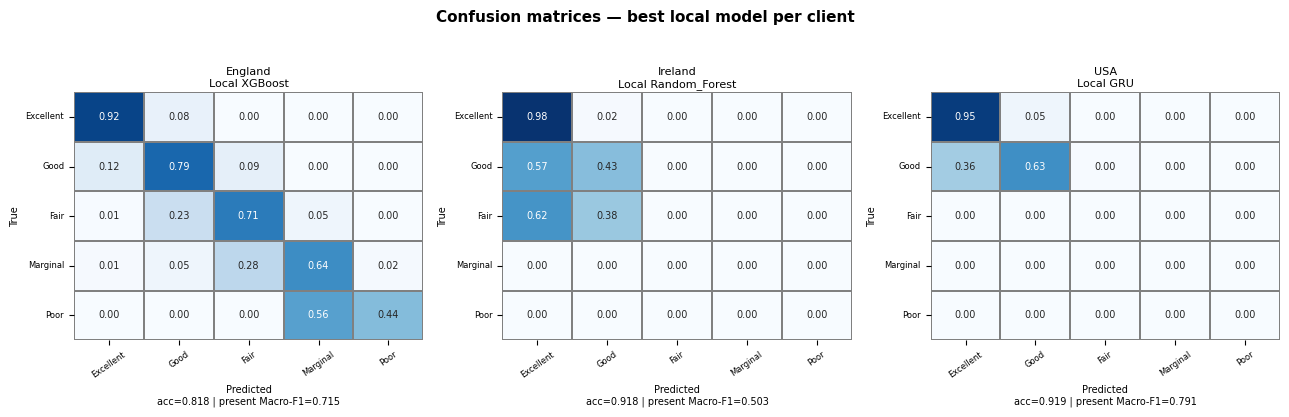

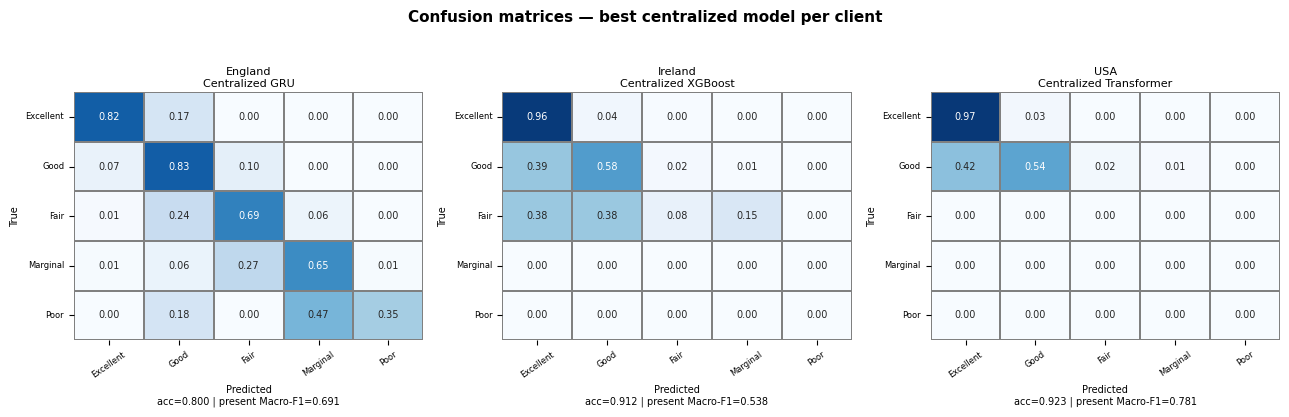

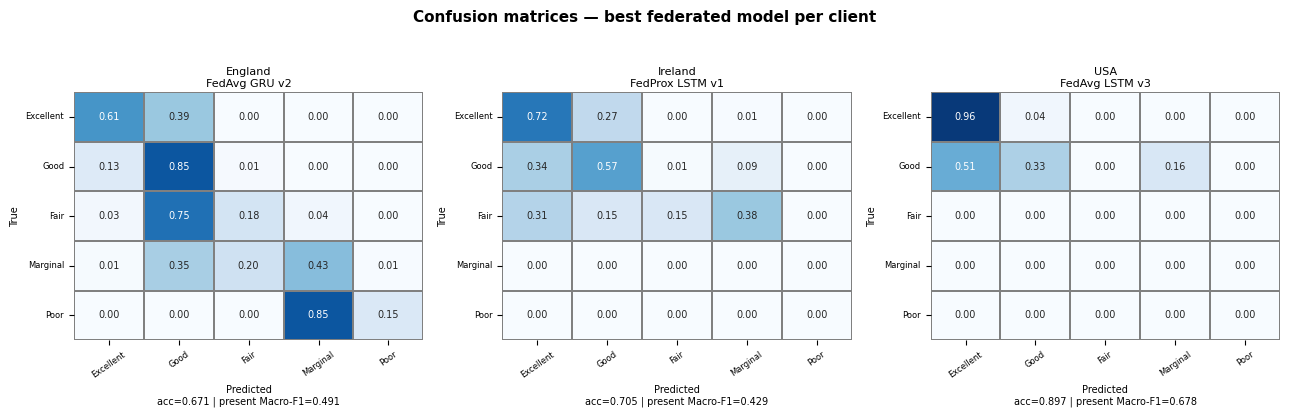

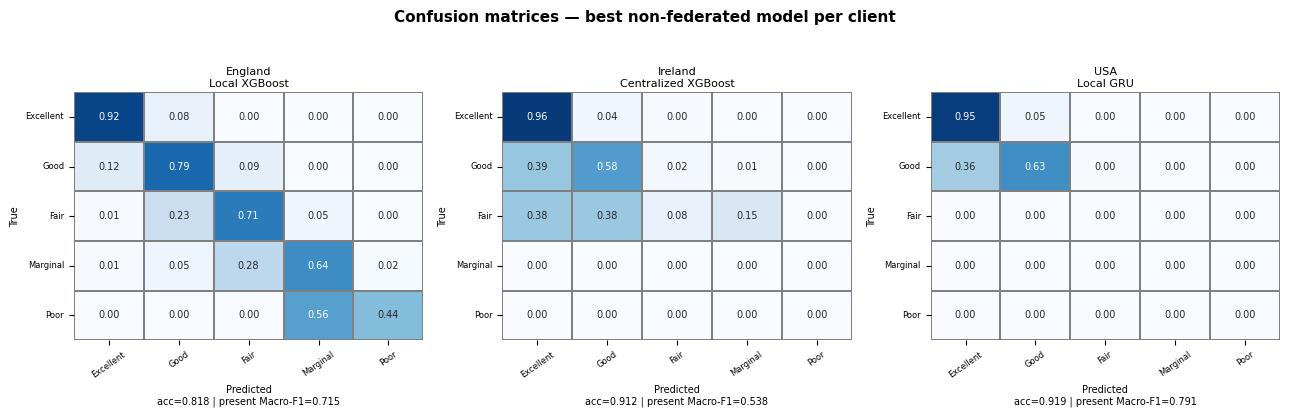

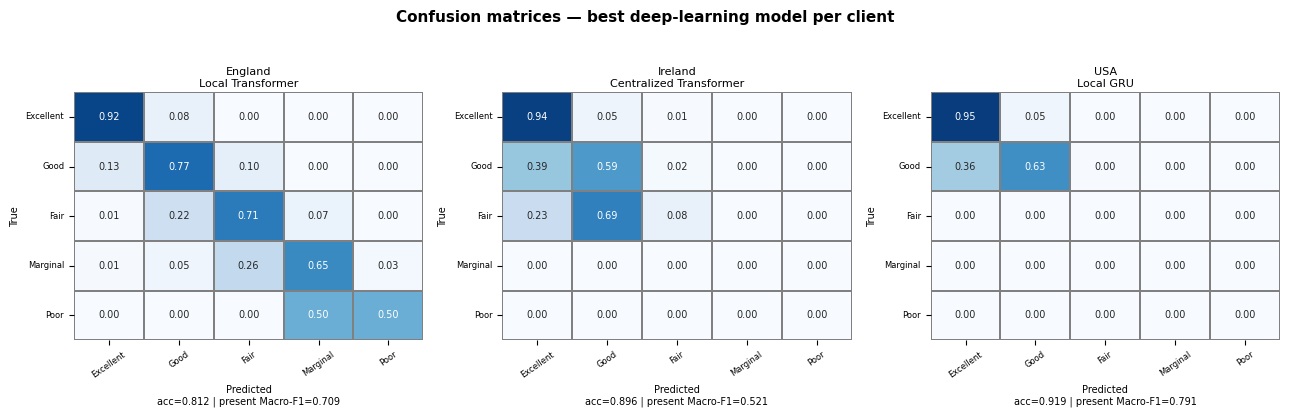

Best-per-client figures saved:
 - cm_best_local_model_per_client_overall.png
 - cm_best_centralized_model_per_client_overall.png
 - cm_best_federated_model_per_client.png
 - cm_best_non_federated_model_per_client_overall.png
 - cm_best_deep_model_per_client.png


In [42]:
# 6.2 — Plot best-per-strategy confusion matrices
best_figures = []
best_figures.append(plot_best_per_client(
    best_local,
    "cm_best_local_model_per_client_overall.png",
    "Confusion matrices — best local model per client",
    show=True,
))
best_figures.append(plot_best_per_client(
    best_centralized,
    "cm_best_centralized_model_per_client_overall.png",
    "Confusion matrices — best centralized model per client",
    show=True,
))
best_figures.append(plot_best_per_client(
    best_federated,
    "cm_best_federated_model_per_client.png",
    "Confusion matrices — best federated model per client",
    show=True,
))
best_figures.append(plot_best_per_client(
    best_non_federated,
    "cm_best_non_federated_model_per_client_overall.png",
    "Confusion matrices — best non-federated model per client",
    show=True,
))
best_figures.append(plot_best_per_client(
    best_deep,
    "cm_best_deep_model_per_client.png",
    "Confusion matrices — best deep-learning model per client",
    show=True,
))

print("Best-per-client figures saved:")
for p in best_figures:
    print(" -", p.name)

## 7. Per-class summaries for thesis tables

These tables give precision, recall, and F1-score behind the best-per-client confusion matrices.


In [43]:
# 7.1 — Per-class precision / recall / F1 for best-model groups

def per_class_summary(selection_df, selection_name):
    summary_rows = []
    for _, row in selection_df.iterrows():
        client = row["Client"]
        item = get_item_by_label(row["Label"])
        y_true, y_pred, _ = load_catalog_preds(item, client)
        rep = classification_report(
            y_true,
            y_pred,
            labels=list(range(N_CLASSES)),
            target_names=CLASS_NAMES,
            zero_division=0,
            output_dict=True,
        )
        for cname in CLASS_NAMES:
            summary_rows.append({
                "Selection": selection_name,
                "Client": client,
                "Category": row["Category"],
                "Model": row["Model"],
                "Class": cname,
                "Precision": round(rep[cname]["precision"], 4),
                "Recall": round(rep[cname]["recall"], 4),
                "F1": round(rep[cname]["f1-score"], 4),
                "Support": int(rep[cname]["support"]),
            })
    return pd.DataFrame(summary_rows)

per_class_all = pd.concat([
    per_class_summary(best_local, "Best local"),
    per_class_summary(best_centralized, "Best centralized"),
    per_class_summary(best_federated, "Best federated"),
    per_class_summary(best_non_federated, "Best non-federated"),
    per_class_summary(best_deep, "Best deep learning"),
], ignore_index=True)

per_class_all.to_csv(OUTPUT_DIR / "n06_selected_best_models_per_class_summary.csv", index=False)
print("Saved:", OUTPUT_DIR / "n06_selected_best_models_per_class_summary.csv")
display(per_class_all)

Saved: /kaggle/working/confusion_matrices/n06_selected_best_models_per_class_summary.csv


,Selection,Client,Category,Model,Class,Precision,Recall,F1,Support
0,Best local,England,Classical ML,Local XGBoost,Excellent,0.8436,0.9229,0.8815,4162
1,Best local,England,Classical ML,Local XGBoost,Good,0.8759,0.7864,0.8287,5832
2,Best local,England,Classical ML,Local XGBoost,Fair,0.5808,0.7132,0.6403,1360
3,Best local,England,Classical ML,Local XGBoost,Marginal,0.7778,0.6444,0.7048,554
4,Best local,England,Classical ML,Local XGBoost,Poor,0.6250,0.4412,0.5172,34
...,...,...,...,...,...,...,...,...,...
70,Best deep learning,USA,Deep learning,Local GRU,Excellent,0.9574,0.9520,0.9547,1771
71,Best deep learning,USA,Deep learning,Local GRU,Good,0.6197,0.6346,0.6271,208
72,Best deep learning,USA,Deep learning,Local GRU,Fair,0.0000,0.0000,0.0000,0
73,Best deep learning,USA,Deep learning,Local GRU,Marginal,0.0000,0.0000,0.0000,0


## 8. Prediction availability audit

This audit checks whether the exact federated models mentioned in the final comparison have saved prediction files. If a model has metrics but no saved predictions, its confusion matrix cannot be generated in N06 unless the original training notebook is rerun and saves the missing predictions.


In [44]:
# 8.1 — Audit exact prediction availability for the corrected N09 best federated models

# Corrected N09 best federated models:
# England -> GRU FedAvg_v2
# Ireland -> LSTM FedProx_v1
# USA     -> LSTM FedAvg_v3

expected_best_files = [
    {
        "Client": "England",
        "Expected_model": "GRU FedAvg_v2",
        "Expected_filename": "fedavg_v2_england_test_preds.npz",
    },
    {
        "Client": "Ireland",
        "Expected_model": "LSTM FedProx_v1",
        "Expected_filename": "lstm_fedprox_v1_ireland_test_preds.npz",
    },
    {
        "Client": "USA",
        "Expected_model": "LSTM FedAvg_v3",
        "Expected_filename": "lstm_fedavg_v3_usa_test_preds.npz",
    },
]

audit_rows = []
for item in expected_best_files:
    found = find_file(item["Expected_filename"])
    audit_rows.append({
        **item,
        "Found": found is not None,
        "Path": str(found or ""),
    })

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(
    OUTPUT_DIR / "n06_exact_best_federated_prediction_availability_audit.csv",
    index=False,
)

display(audit_df)

assert audit_df["Found"].all(), (
    "One or more exact prediction files required by the corrected N09 selection "
    "are still missing. Attach the updated GRU and LSTM output archives."
)

# Confirm that the automatically selected N06 federated models match corrected N09.
expected_models = {
    "England": "FedAvg GRU v2",
    "Ireland": "FedProx LSTM v1",
    "USA": "FedAvg LSTM v3",
}

selection_check_rows = []
for _, row in best_federated.iterrows():
    client = row["Client"]
    expected_model = expected_models[client]
    actual_model = row["Model"]
    selection_check_rows.append({
        "Client": client,
        "Expected_model_from_N09": expected_model,
        "Selected_model_in_N06": actual_model,
        "Matches": actual_model == expected_model,
        "Macro_F1_Present": row["Macro_F1_Present"],
    })

selection_check_df = pd.DataFrame(selection_check_rows)
selection_check_df.to_csv(
    OUTPUT_DIR / "n06_best_federated_consistency_with_n09.csv",
    index=False,
)

display(selection_check_df)

assert selection_check_df["Matches"].all(), (
    "N06 best federated models do not match corrected N09. "
    "Check attached archive versions and candidate availability."
)

print("Exact best-federated predictions are available, and N06 matches corrected N09.")


,Client,Expected_model,Expected_filename,Found,Path
0,England,GRU FedAvg_v2,fedavg_v2_england_test_preds.npz,True,/kaggle/input/datasets/hebacheblal/gru-baselin...
1,Ireland,LSTM FedProx_v1,lstm_fedprox_v1_ireland_test_preds.npz,True,/kaggle/input/datasets/hebacheblal/lstm-baseli...
2,USA,LSTM FedAvg_v3,lstm_fedavg_v3_usa_test_preds.npz,True,/kaggle/input/datasets/hebacheblal/lstm-baseli...


,Client,Expected_model_from_N09,Selected_model_in_N06,Matches,Macro_F1_Present
0,England,FedAvg GRU v2,FedAvg GRU v2,True,0.491482
1,Ireland,FedProx LSTM v1,FedProx LSTM v1,True,0.429414
2,USA,FedAvg LSTM v3,FedAvg LSTM v3,True,0.678483


Exact best-federated predictions are available, and N06 matches corrected N09.


## 9. Reading guide

Use the confusion matrices carefully:

- England is the only active client where all five classes are present in the test set.
- Ireland has very few Fair samples and no Marginal/Poor samples in the test set.
- USA test contains only Excellent and Good classes.
- Empty rows mean no test samples for that class, not necessarily model failure.
- Confusion matrices should be interpreted together with present-class Macro-F1, balanced accuracy, and the split-level class distribution table.


In [45]:
# 10 — Zip all updated N06 outputs for download
zip_path = shutil.make_archive(
    base_name=str(WORKING_ROOT / "confusion_matrices"),
    format="zip",
    root_dir=OUTPUT_DIR,
)
print(f"Archive created: {zip_path}")

print("\nOutput files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)

Archive created: /kaggle/working/confusion_matrices.zip

Output files:
 - cm_all_available_federated_deep_learning_models.png
 - cm_all_centralized_classical_ml_models.png
 - cm_all_centralized_deep_learning_models.png
 - cm_all_local_classical_ml_models.png
 - cm_all_local_deep_learning_models.png
 - cm_best_centralized_model_per_client_overall.png
 - cm_best_deep_model_per_client.png
 - cm_best_federated_model_per_client.png
 - cm_best_local_model_per_client_overall.png
 - cm_best_non_federated_model_per_client_overall.png
 - cm_classical_ml_centralized_centralized_catboost.png
 - cm_classical_ml_centralized_centralized_logistic_regression.png
 - cm_classical_ml_centralized_centralized_random_forest.png
 - cm_classical_ml_centralized_centralized_xgboost.png
 - cm_classical_ml_local_local_catboost.png
 - cm_classical_ml_local_local_logistic_regression.png
 - cm_classical_ml_local_local_random_forest.png
 - cm_classical_ml_local_local_xgboost.png
 - cm_deep_learning_centralized_central